# Kasus 08: EDA, Pembersihan Data, & Evaluasi Model
**Hub Ekspedisi Bandung — Prediksi Keterlambatan Paket**

In [1]:
import sys
sys.path.append('..')
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from src.features import clean_dataframe

raw = pd.read_csv('../data/raw.csv')
print('Ukuran data mentah:', raw.shape)
print('Jumlah duplikat id_resi:', raw.duplicated(subset=['id_resi']).sum())
print('\nNilai kosong per kolom:\n', raw.isnull().sum())
print('\nJumlah kategori kota_tujuan (mentah):', raw['kota_tujuan'].nunique())
print('Jumlah kategori layanan (mentah):', raw['layanan'].nunique())
print('Berat <= 0:', (raw['berat_kg'] <= 0).sum(), '| Berat >= 100 (satuan gram):', (raw['berat_kg'] >= 100).sum())

Ukuran data mentah: (40500, 13)
Jumlah duplikat id_resi: 500

Nilai kosong per kolom:
 id_resi                0
tanggal_pickup         0
jam_pickup             0
kota_tujuan            0
jarak_km             813
jumlah_transit         0
layanan                0
janji_hari             0
berat_kg               0
metode_bayar           0
cuaca_saat_pickup    406
volume_hub_hari        0
terlambat              0
dtype: int64

Jumlah kategori kota_tujuan (mentah): 28
Jumlah kategori layanan (mentah): 7
Berat <= 0: 81 | Berat >= 100 (satuan gram): 1208


Train (2025): 26633 baris | Terlambat: 17.78%
Val (Q1 2026): 6623 baris | Terlambat: 21.88%
Test (Q2 2026): 6744 baris | Terlambat: 13.92%


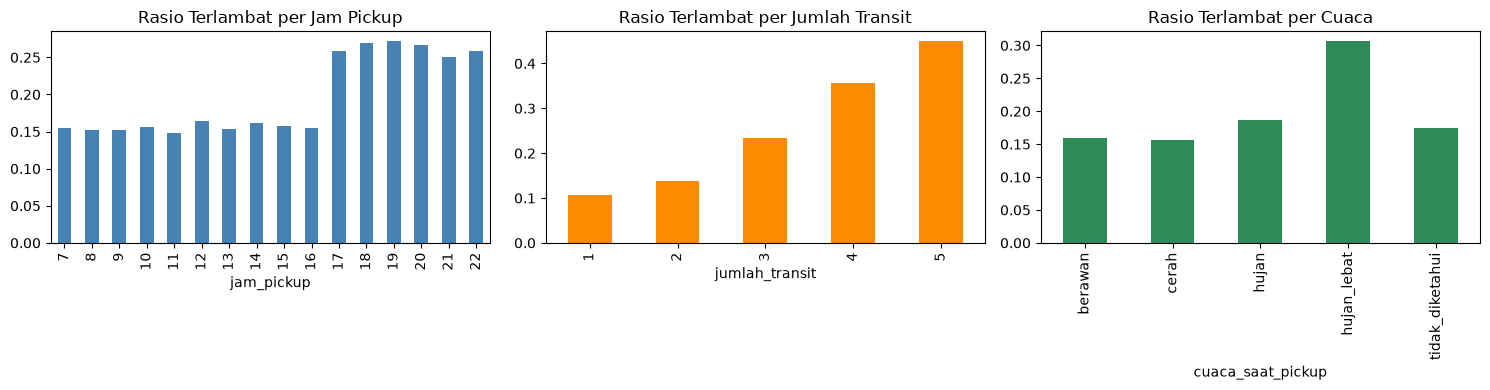

In [2]:
df = clean_dataframe(raw, deduplicate=True)
train = df[df['dt'] <= '2025-12-31'].copy()
val = df[(df['dt'] >= '2026-01-01') & (df['dt'] <= '2026-03-31')].copy()
test = df[df['dt'] >= '2026-04-01'].copy()

print(f'Train (2025): {len(train)} baris | Terlambat: {train["terlambat"].mean():.2%}')
print(f'Val (Q1 2026): {len(val)} baris | Terlambat: {val["terlambat"].mean():.2%}')
print(f'Test (Q2 2026): {len(test)} baris | Terlambat: {test["terlambat"].mean():.2%}')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
train.groupby('jam_pickup')['terlambat'].mean().plot(kind='bar', ax=axes[0], title='Rasio Terlambat per Jam Pickup', color='steelblue')
train.groupby('jumlah_transit')['terlambat'].mean().plot(kind='bar', ax=axes[1], title='Rasio Terlambat per Jumlah Transit', color='darkorange')
train.groupby('cuaca_saat_pickup')['terlambat'].mean().plot(kind='bar', ax=axes[2], title='Rasio Terlambat per Cuaca', color='seagreen')
plt.tight_layout()
plt.show()

In [3]:
with open('../artifacts/metadata.json', 'r', encoding='utf-8') as f:
    meta = json.load(f)

print('=== RINGKASAN METRIK MODEL ===')
print(json.dumps(meta['metrics'], indent=2))

=== RINGKASAN METRIK MODEL ===
{
  "validation": {
    "baseline_pr_auc": 0.6455,
    "final_pr_auc": 0.6556,
    "final_roc_auc": 0.84,
    "optimal_threshold_summary": {
      "threshold": 0.111,
      "total_cost": 19255000,
      "avg_cost_per_pkg": 2907.29,
      "tp": 1279,
      "fp": 2151,
      "tn": 3023,
      "fn": 170
    }
  },
  "test": {
    "baseline_pr_auc": 0.3563,
    "final_pr_auc": 0.3665,
    "final_roc_auc": 0.7559,
    "total_cost_idr": 22300000,
    "avg_cost_per_pkg_idr": 3306.64,
    "confusion_matrix": {
      "tp": 712,
      "fp": 2190,
      "tn": 3615,
      "fn": 227
    }
  }
}
